<a href="https://colab.research.google.com/github/Yahya1805/PCVK_GANJIL_2026/blob/main/WEEK9_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

M.Yahya Irvansyah
244107020032
TI-3G

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Nomor 2 — Import library dan persiapan citra

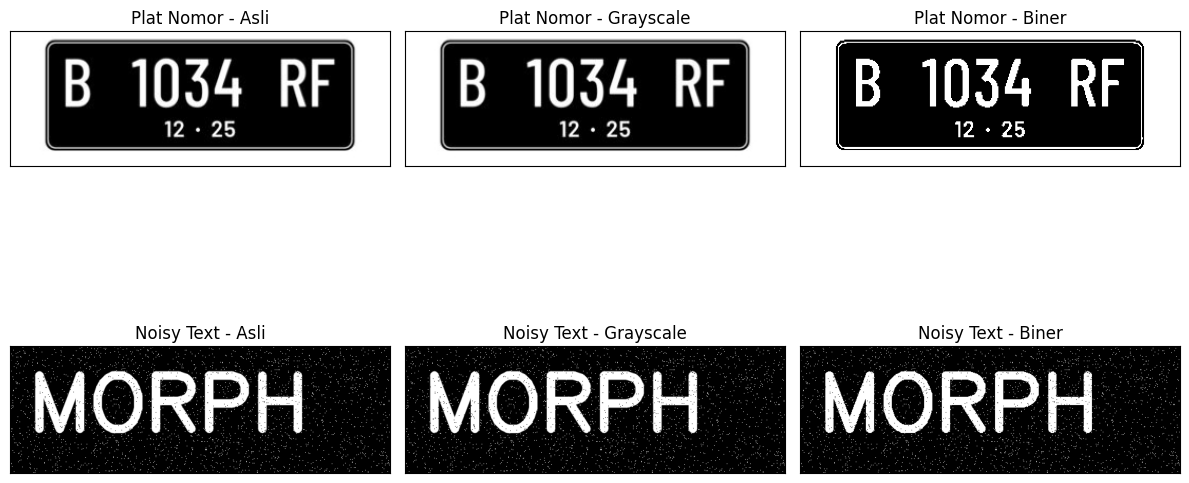

In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Lokasi dua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Noisy Text']

# Tampilan 2 gambar: masing-masing 3 tahapan
plt.figure(figsize=(12, 8))

for i, path in enumerate(img_paths):

    # Membaca gambar
    img_color = cv2.imread(path)

    if img_color is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Grayscale
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

    # Thresholding menjadi biner
    ret, img_binary = cv2.threshold(
        img_gray, 127, 255, cv2.THRESH_BINARY
    )

    # Baris gambar: 1 untuk plat nomor, 2 untuk noisy text
    baris = i * 3

    plt.subplot(2, 3, baris + 1)
    plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
    plt.title(f'{judul_gambar[i]} - Asli')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(2, 3, baris + 2)
    plt.imshow(img_gray, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Grayscale')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(2, 3, baris + 3)
    plt.imshow(img_binary, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Biner')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


# Nomor 3 — Dilasi manual dengan SED cross 3 × 3

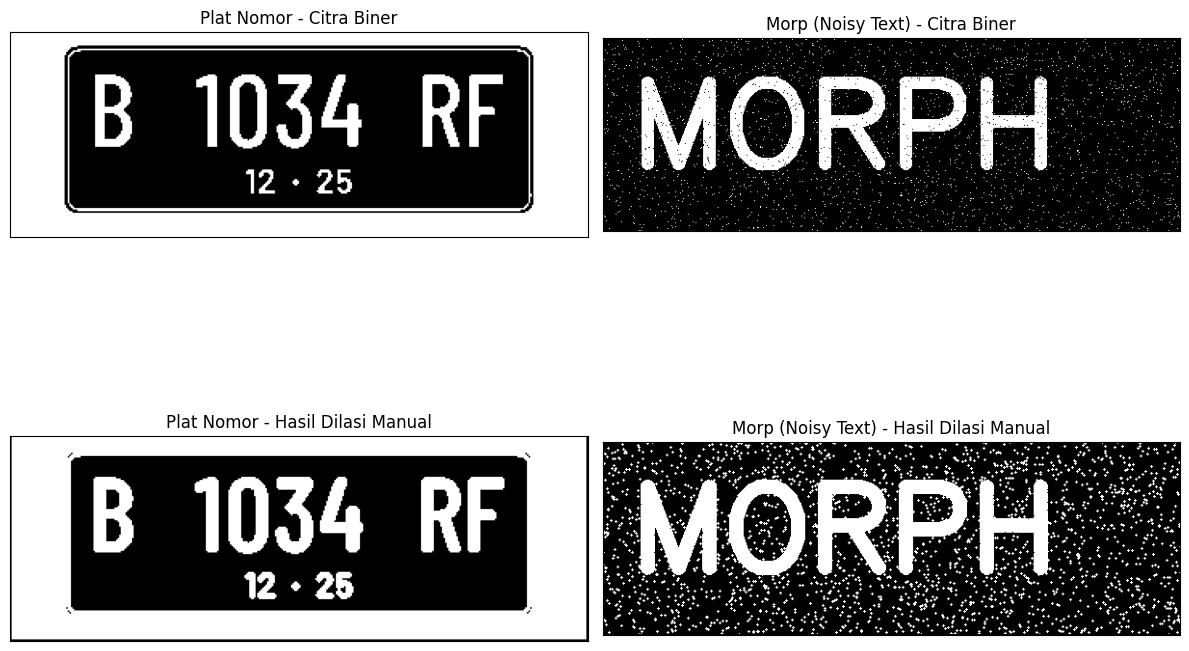

In [4]:
# Dilasi Tanpa Library Morphology OpenCV

def dilasi_citra(F, w):
    p, q = F.shape

    # Structuring Element cross 3 x 3
    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]
    ], dtype=np.uint8)

    constant = (w - 1) // 2
    imgD = np.zeros((p, q), dtype=np.uint8)

    for i in range(constant, p - constant):
        for j in range(constant, q - constant):
            temp = F[
                i-constant:i+constant+1,
                j-constant:j+constant+1
            ]

            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

# Menampilkan kedua gambar: biner di atas, hasil dilasi di bawah
plt.figure(figsize=(12, 10))

for i, path in enumerate(img_paths):
    img_color = cv2.imread(path)

    if img_color is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    _, img_binary = cv2.threshold(
        img_gray, 127, 255, cv2.THRESH_BINARY
    )

    imgD_manual = dilasi_citra(img_binary, 3)

    # Citra biner (atas)
    plt.subplot(2, 2, i + 1)
    plt.imshow(img_binary, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Biner')
    plt.xticks([])
    plt.yticks([])

    # Hasil dilasi manual (bawah)
    plt.subplot(2, 2, i + 3)
    plt.imshow(imgD_manual, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Hasil Dilasi Manual')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 4 — Dilasi menggunakan library OpenCV

Structuring Element:
[[0 1 0]
 [1 1 1]
 [0 1 0]]


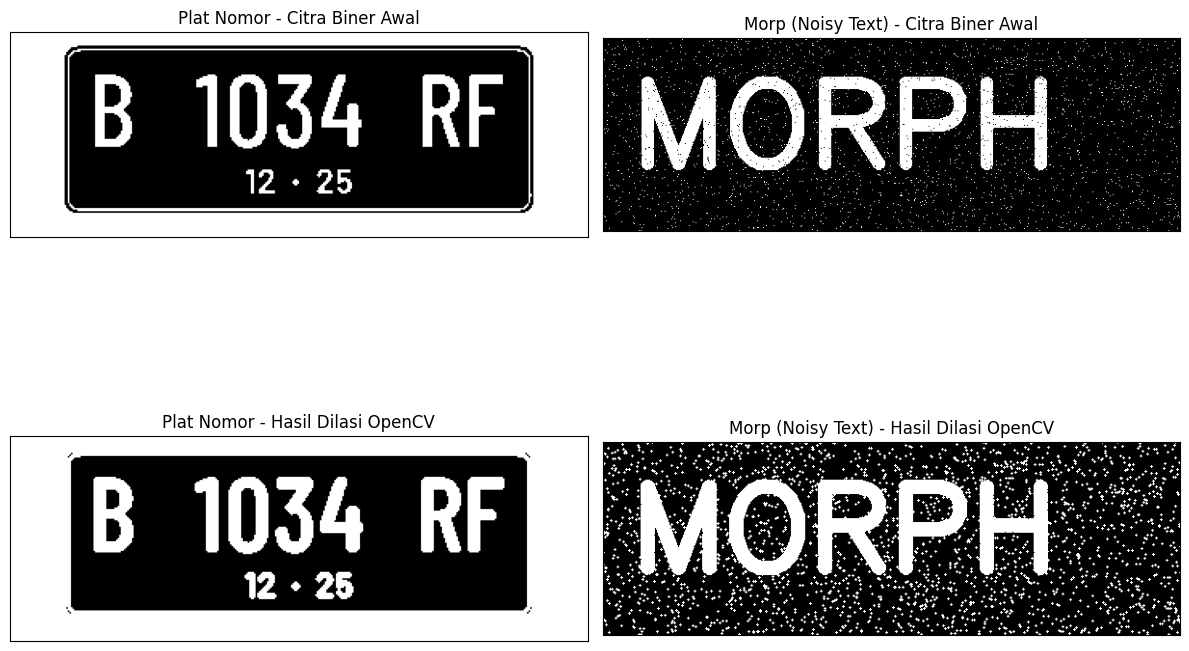

In [5]:
# Dilasi Menggunakan Library Morphology OpenCV

# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

# Structuring Element cross 3 x 3
kernel = cv2.getStructuringElement(
    cv2.MORPH_CROSS, (3, 3)
)

print("Structuring Element:")
print(kernel)

# Menampilkan perbandingan kedua gambar
plt.figure(figsize=(12, 10))

for i, path in enumerate(img_paths):
    img_color = cv2.imread(path)

    if img_color is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Konversi ke grayscale dan biner
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
    _, img_binary = cv2.threshold(
        img_gray, 127, 255, cv2.THRESH_BINARY
    )

    # Proses dilasi menggunakan OpenCV
    dilasi = cv2.dilate(
        img_binary, kernel, iterations=1
    )

    # Citra biner awal (atas)
    plt.subplot(2, 2, i + 1)
    plt.imshow(img_binary, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Biner Awal')
    plt.xticks([])
    plt.yticks([])

    # Hasil dilasi (bawah)
    plt.subplot(2, 2, i + 3)
    plt.imshow(dilasi, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Hasil Dilasi OpenCV')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 5 — Erosi manual dengan SE square 5 × 5

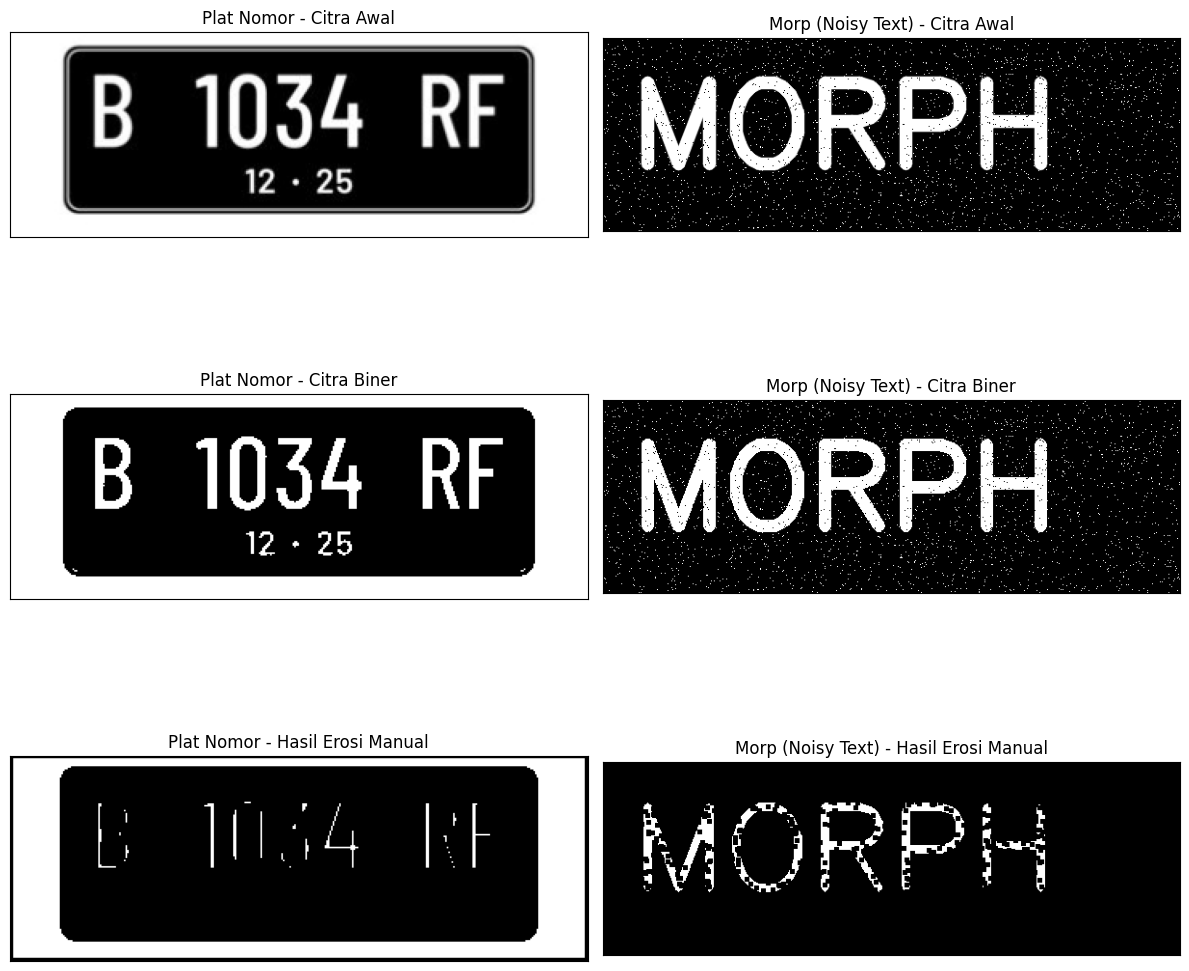

In [6]:
# Erosi Tanpa Library Morphology OpenCV

def erosi_citra(F, k):
    m, n = F.shape

    # Structuring Element square k x k
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2

    # Citra hasil erosi
    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses erosi manual
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i-constant:i+constant+1,
                j-constant:j+constant+1
            ]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

# Menampilkan perbandingan kedua gambar
plt.figure(figsize=(12, 12))

for i, path in enumerate(img_paths):
    img_color = cv2.imread(path)

    if img_color is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Konversi ke grayscale
    img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

    # Thresholding sesuai jobsheet
    ret1, thresh1 = cv2.threshold(
        img_gray, 175, 255, cv2.THRESH_BINARY
    )

    # Erosi manual dengan SE square 5 x 5
    k = 5
    imgE = erosi_citra(thresh1, k)

    # Citra awal (baris pertama)
    plt.subplot(3, 2, i + 1)
    plt.imshow(img_gray, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Awal')
    plt.xticks([])
    plt.yticks([])

    # Citra biner (baris kedua)
    plt.subplot(3, 2, i + 3)
    plt.imshow(thresh1, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Biner')
    plt.xticks([])
    plt.yticks([])

    # Hasil erosi (baris ketiga)
    plt.subplot(3, 2, i + 5)
    plt.imshow(imgE, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Hasil Erosi Manual')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 6 — Erosi menggunakan library OpenCV (SE square 5 × 5)

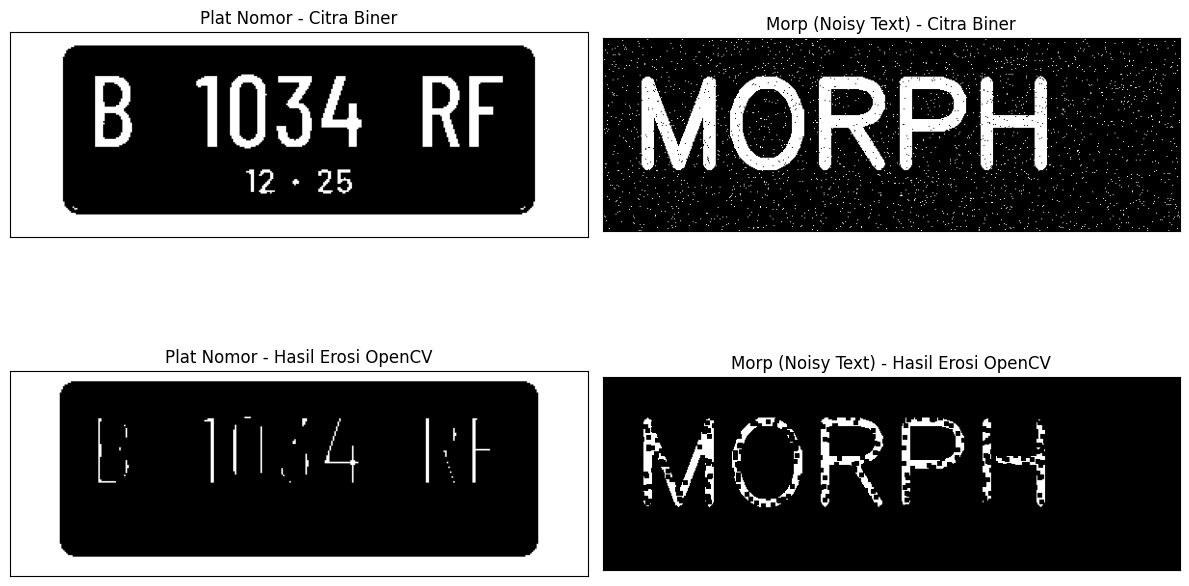

In [7]:
# Nomor 6: Erosi Menggunakan Library Morphology OpenCV

# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

# Structuring Element square 5 x 5
kernel = np.ones((5, 5), dtype=np.uint8)

# Menampilkan perbandingan kedua gambar
plt.figure(figsize=(12, 8))

for i, path in enumerate(img_paths):
    # Membaca citra grayscale
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Mengubah grayscale menjadi citra biner
    ret, thresh = cv2.threshold(
        img, 175, 255, cv2.THRESH_BINARY
    )

    # Proses erosi menggunakan OpenCV
    erosion = cv2.erode(
        thresh, kernel, iterations=1
    )

    # Citra biner (baris atas)
    plt.subplot(2, 2, i + 1)
    plt.imshow(thresh, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Biner')
    plt.xticks([])
    plt.yticks([])

    # Hasil erosi (baris bawah)
    plt.subplot(2, 2, i + 3)
    plt.imshow(erosion, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Hasil Erosi OpenCV')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 7A — Opening tanpa library morphology OpenCV

<Figure size 800x800 with 0 Axes>

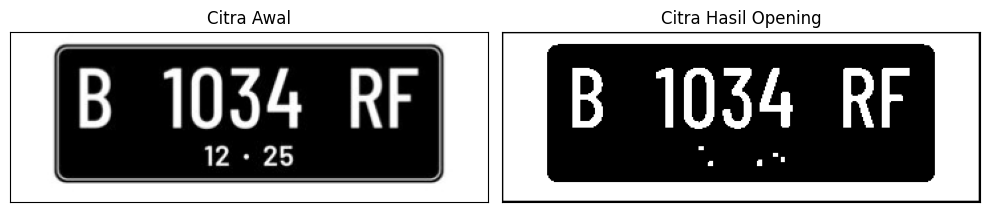

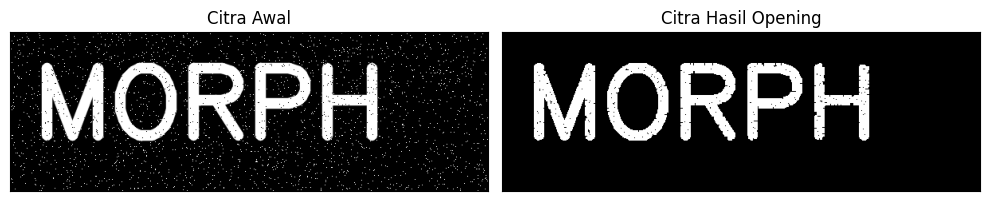

In [8]:
# Nomor 7: Operasi Opening Tanpa Library Morphology OpenCV

# Fungsi opening manual: erosi dilanjutkan dilasi
def opening_manual(F, k):
    SE = np.ones((k, k), dtype=np.uint8)
    hasil_erosi = erosi_citra(F, k)
    hasil_opening = dilasi_citra_square(hasil_erosi, k)
    return hasil_opening


# Fungsi dilasi manual dengan SE square
def dilasi_citra_square(F, k):
    m, n = F.shape
    constant = (k - 1) // 2
    SE = np.ones((k, k), dtype=np.uint8)
    imgD = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i-constant:i+constant+1,
                j-constant:j+constant+1
            ]
            imgD[i, j] = np.max(temp * SE)

    return imgD


# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

plt.figure(figsize=(8, 8))

for i, path in enumerate(img_paths):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Thresholding
    _, thresh = cv2.threshold(
        img, 127, 255, cv2.THRESH_BINARY
    )

    # Opening manual menggunakan SE square 3 x 3
    k = 3
    imgO = opening_manual(thresh, k)

    plt.figure(figsize=(10, 3))

    plt.subplot(121)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(122)
    plt.imshow(imgO, cmap='gray')
    plt.title('Citra Hasil Opening')
    plt.xticks([])
    plt.yticks([])

    plt.tight_layout()
    plt.show()

# Nomor 7B — Opening menggunakan library OpenCV

<Figure size 800x800 with 0 Axes>

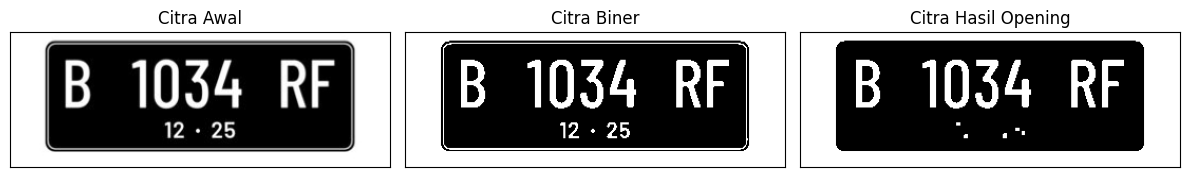

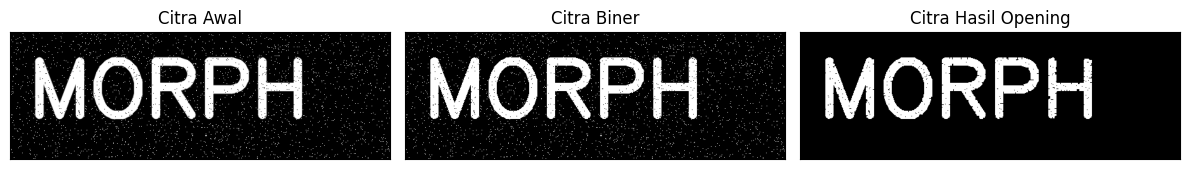

In [9]:
# Nomor 7: Operasi Opening Menggunakan Library Morphology OpenCV

# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

# Structuring Element square 3 x 3
kernel = np.ones((3, 3), dtype=np.uint8)

plt.figure(figsize=(8, 8))

for i, path in enumerate(img_paths):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Thresholding
    _, thresh = cv2.threshold(
        img, 127, 255, cv2.THRESH_BINARY
    )

    # Opening menggunakan OpenCV
    openn = cv2.morphologyEx(
        thresh, cv2.MORPH_OPEN, kernel
    )

    plt.figure(figsize=(12, 3))

    plt.subplot(131)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(132)
    plt.imshow(thresh, cmap='gray')
    plt.title('Citra Biner')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(133)
    plt.imshow(openn, cmap='gray')
    plt.title('Citra Hasil Opening')
    plt.xticks([])
    plt.yticks([])

    plt.tight_layout()
    plt.show()

# 8A Closing tanpa Library Morphology OpenCV

<Figure size 800x800 with 0 Axes>

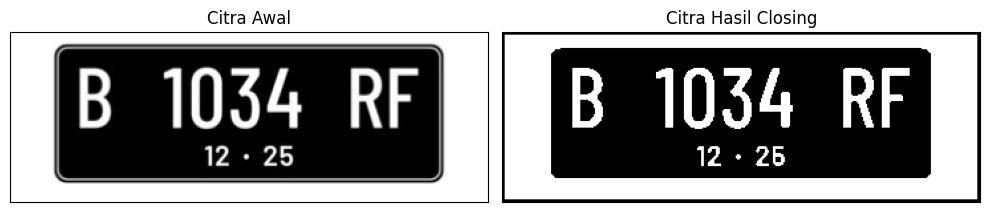

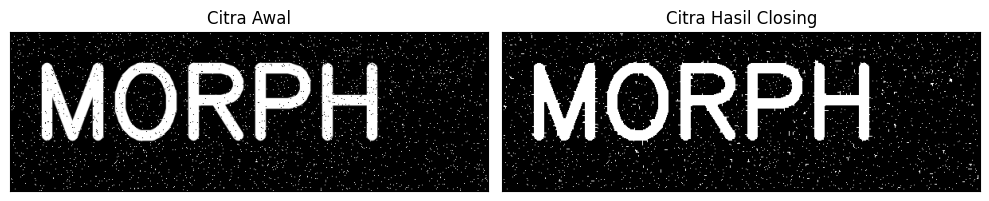

In [10]:
# Nomor 8: Operasi Closing Tanpa Library Morphology OpenCV

def closing_manual(F, k):
    # Closing = dilasi terlebih dahulu, kemudian erosi
    hasil_dilasi = dilasi_citra_square(F, k)
    hasil_closing = erosi_citra(hasil_dilasi, k)
    return hasil_closing


# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

plt.figure(figsize=(8, 8))

for i, path in enumerate(img_paths):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Thresholding
    _, thresh = cv2.threshold(
        img, 127, 255, cv2.THRESH_BINARY
    )

    # Closing manual menggunakan SE square 3 x 3
    k = 3
    imgC = closing_manual(thresh, k)

    plt.figure(figsize=(10, 3))

    plt.subplot(121)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(122)
    plt.imshow(imgC, cmap='gray')
    plt.title('Citra Hasil Closing')
    plt.xticks([])
    plt.yticks([])

    plt.tight_layout()
    plt.show()

# 8B Closing dengan Library Morphology OpenCV

<Figure size 800x800 with 0 Axes>

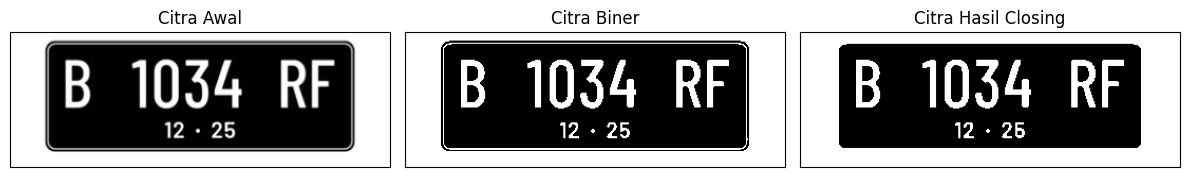

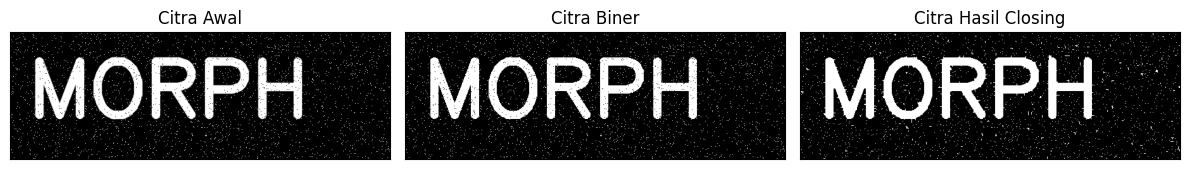

In [11]:
# Nomor 8: Operasi Closing Menggunakan Library Morphology OpenCV

# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

# Structuring Element square 3 x 3
kernel = np.ones((3, 3), dtype=np.uint8)

plt.figure(figsize=(8, 8))

for i, path in enumerate(img_paths):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Thresholding
    _, thresh = cv2.threshold(
        img, 127, 255, cv2.THRESH_BINARY
    )

    # Closing menggunakan OpenCV
    closs = cv2.morphologyEx(
        thresh, cv2.MORPH_CLOSE, kernel
    )

    plt.figure(figsize=(12, 3))

    plt.subplot(131)
    plt.imshow(img, cmap='gray')
    plt.title('Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(132)
    plt.imshow(thresh, cmap='gray')
    plt.title('Citra Biner')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(133)
    plt.imshow(closs, cmap='gray')
    plt.title('Citra Hasil Closing')
    plt.xticks([])
    plt.yticks([])

    plt.tight_layout()
    plt.show()

# Nomor 9A: Dilasi dengan Structuring Element Cross 3x3

Structuring Element Cross 3x3


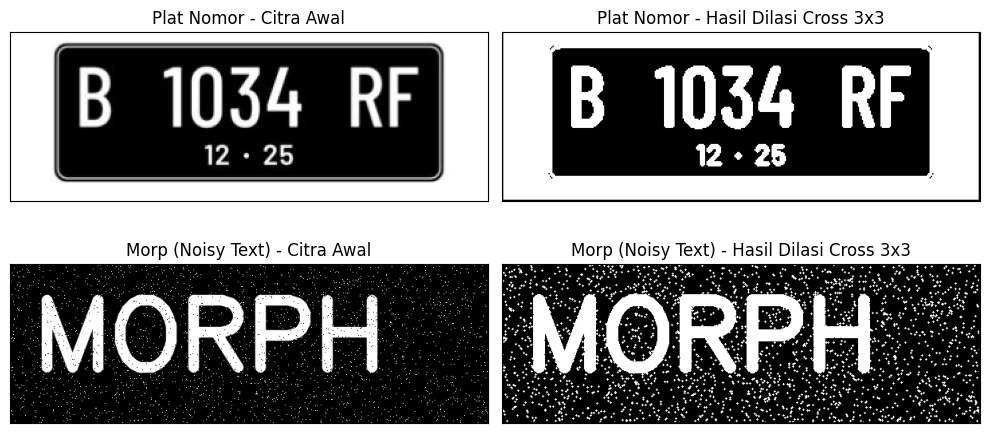

In [12]:
# Nomor 9A: Dilasi dengan Structuring Element Cross 3x3

def dilasi_citra(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Structuring Element Cross 3x3
    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses dilasi manual
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

print('Structuring Element Cross 3x3')

plt.figure(figsize=(10, 5))

for i, path in enumerate(img_paths):
    img_d = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img_d is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Thresholding
    _, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

    # Dilasi Cross 3x3
    imgD = dilasi_citra(thresh, 3)

    # Citra awal
    plt.subplot(2, 2, i * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Awal')
    plt.xticks([])
    plt.yticks([])

    # Hasil dilasi
    plt.subplot(2, 2, i * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Hasil Dilasi Cross 3x3')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 9B: Dilasi dengan Structuring Element Cross 5x5

Structuring Element Cross 5x5


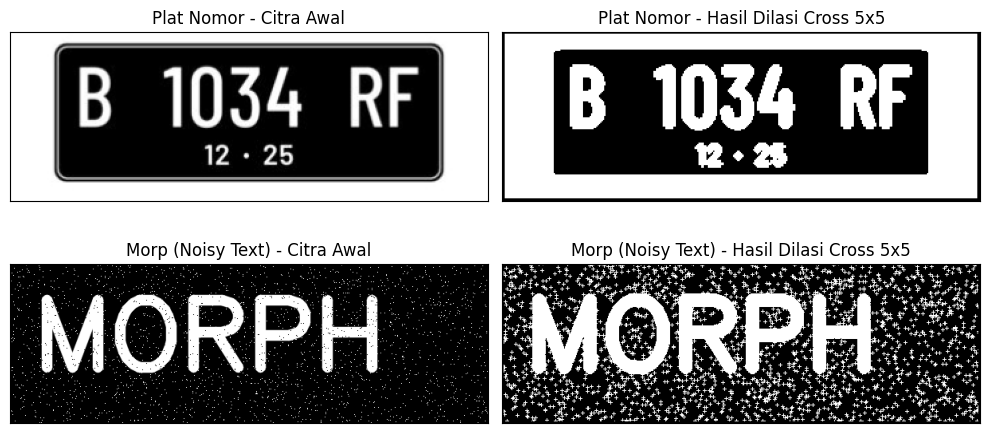

In [13]:
# Nomor 9B: Dilasi dengan Structuring Element Cross 5x5

def dilasi_citra_cross5(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Structuring Element Cross 5x5
    SED = np.array([
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0],
        [1, 1, 1, 1, 1],
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2

    # Proses dilasi manual
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


# Lokasi kedua gambar
img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

print('Structuring Element Cross 5x5')

plt.figure(figsize=(10, 5))

for i, path in enumerate(img_paths):
    img_d = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img_d is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    # Thresholding
    _, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

    # Dilasi Cross 5x5
    imgD = dilasi_citra_cross5(thresh, 5)

    # Citra awal
    plt.subplot(2, 2, i * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Awal')
    plt.xticks([])
    plt.yticks([])

    # Hasil dilasi
    plt.subplot(2, 2, i * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Hasil Dilasi Cross 5x5')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 10A. Dilasi Circular 3×3

Structuring Element Circular 3x3


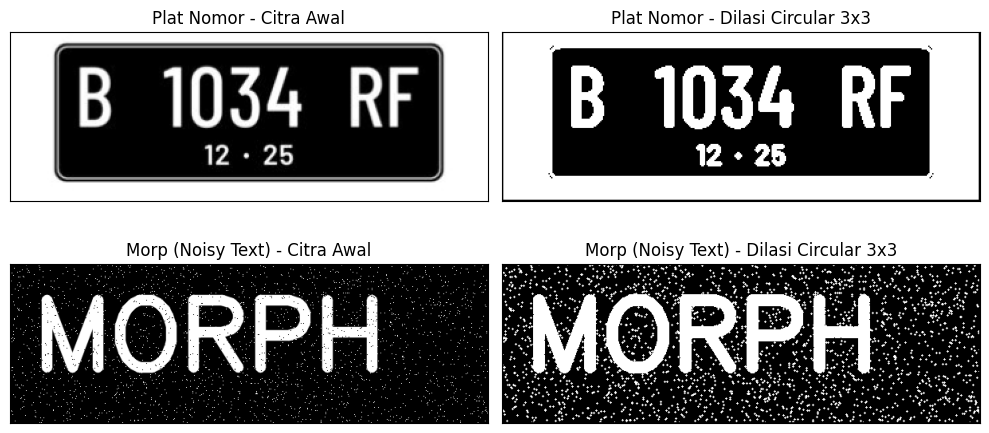

In [14]:
# Nomor 10A: Dilasi Circular 3x3 tanpa library morphology

def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Structuring Element Circular
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i-constant1:i+constant1+1,
                j-constant1:j+constant1+1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


img_paths = [
    '/content/drive/MyDrive/PCVK/Pertemuan 9/PlatNomor1.jpg',
    '/content/drive/MyDrive/PCVK/Pertemuan 9/noisy_text.png'
]

judul_gambar = ['Plat Nomor', 'Morp (Noisy Text)']

print('Structuring Element Circular 3x3')

plt.figure(figsize=(10, 5))

for i, path in enumerate(img_paths):
    img_d = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img_d is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    _, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
    imgD = dilasi_circular(thresh, 3)

    plt.subplot(2, 2, i * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(2, 2, i * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Dilasi Circular 3x3')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 10B Dilasi Circular 5×5

Structuring Element Circular 5x5


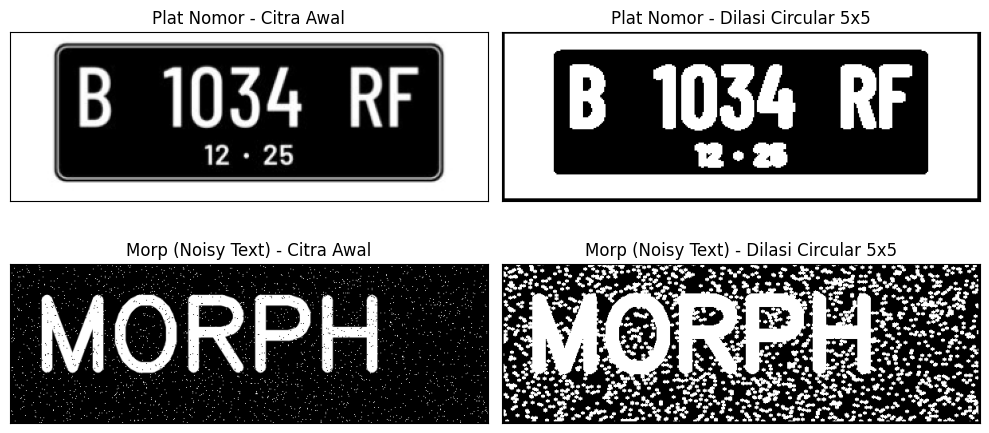

In [15]:
# Nomor 10B: Dilasi Circular 5x5 tanpa library morphology

print('Structuring Element Circular 5x5')

plt.figure(figsize=(10, 5))

for i, path in enumerate(img_paths):
    img_d = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img_d is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    _, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)
    imgD = dilasi_circular(thresh, 5)

    plt.subplot(2, 2, i * 2 + 1)
    plt.imshow(img_d, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(2, 2, i * 2 + 2)
    plt.imshow(imgD, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Dilasi Circular 5x5')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 11A. Erosi Rectangle 3×5

Structuring Element Rectangle 3x5


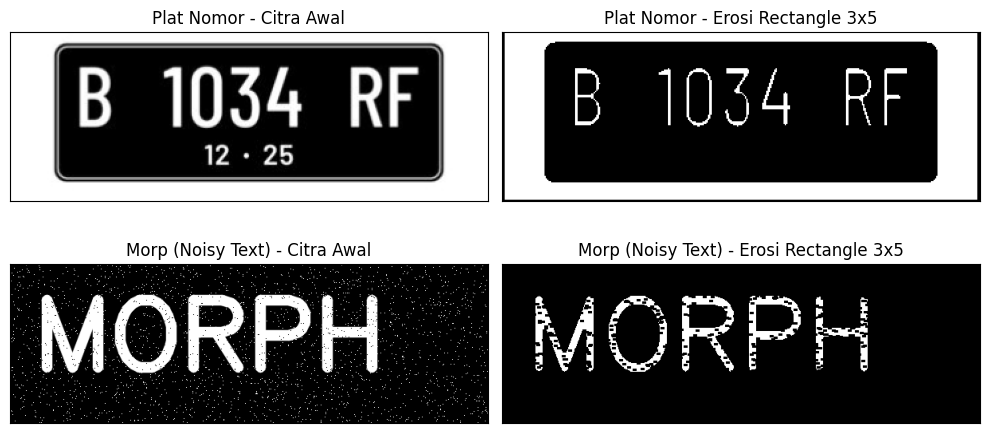

In [16]:
# Nomor 11A: Erosi Rectangle 3x5 tanpa library morphology

def erosi_rectangle(F, lebar, tinggi):
    m, n = F.shape

    # Structuring Element Rectangle
    SE = cv2.getStructuringElement(
        cv2.MORPH_RECT, (lebar, tinggi)
    )

    pad_y = tinggi // 2
    pad_x = lebar // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(pad_y, m - pad_y):
        for j in range(pad_x, n - pad_x):
            temp = F[
                i-pad_y:i+pad_y+1,
                j-pad_x:j+pad_x+1
            ]

            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('Structuring Element Rectangle 3x5')

plt.figure(figsize=(10, 5))

for i, path in enumerate(img_paths):
    img_e = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img_e is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    _, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)

    # OpenCV menggunakan ukuran (lebar, tinggi)
    imgE = erosi_rectangle(thresh1, 5, 3)

    plt.subplot(2, 2, i * 2 + 1)
    plt.imshow(img_e, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(2, 2, i * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Erosi Rectangle 3x5')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

# Nomor 11B Erosi Rectangle 5×7

Structuring Element Rectangle 5x7


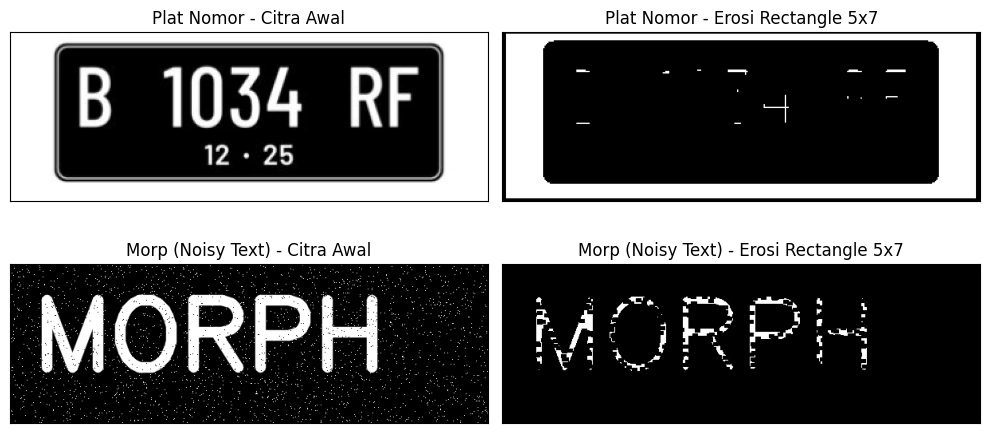

In [17]:
# Nomor 11B: Erosi Rectangle 5x7 tanpa library morphology

print('Structuring Element Rectangle 5x7')

plt.figure(figsize=(10, 5))

for i, path in enumerate(img_paths):
    img_e = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img_e is None:
        print(f'Gambar tidak ditemukan: {path}')
        continue

    _, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)

    # Rectangle lebar 7, tinggi 5
    imgE = erosi_rectangle(thresh1, 7, 5)

    plt.subplot(2, 2, i * 2 + 1)
    plt.imshow(img_e, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Citra Awal')
    plt.xticks([])
    plt.yticks([])

    plt.subplot(2, 2, i * 2 + 2)
    plt.imshow(imgE, cmap='gray')
    plt.title(f'{judul_gambar[i]} - Erosi Rectangle 5x7')
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()